# **실습 개요**

여러분은 한국은행(가상) 화폐 감식팀에 합류한 데이터 분석가입니다.<br>시중에 위조 지폐가 꾸준히 발견되면서,
지폐 스캐너로 촬영한 이미지를 웨이블릿 변환(Wavelet Transform)하여 얻은 통계적 특징만으로 <br>**진짜 지폐와 위조 지폐를 자동으로 구분**하는
모델을 만들어 달라는 요청을 받았습니다.

스캐너 장비 특성상 일부 측정값에는 결측치가 있고, 장비 오작동으로 인한 이상치, 중복 스캔 데이터도 섞여 있습니다. <br>
이 데이터를 정제하고 **로지스틱 회귀(Logistic Regression)** 모델을 학습시켜, 새로운 지폐가 들어왔을 때 진위 여부를 예측해봅시다.

## **데이터셋 설명**

지폐 이미지를 웨이블릿 변환하여 추출한 통계적 특징 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| note_id | 지폐 스캔 고유 ID |
| wavelet_variance | 웨이블릿 변환 이미지의 분산 (값의 퍼짐 정도) |
| wavelet_skewness | 웨이블릿 변환 이미지의 왜도 (비대칭 정도) |
| wavelet_curtosis | 웨이블릿 변환 이미지의 첨도 (뾰족한 정도) |
| image_entropy | 이미지의 엔트로피 (무질서도) |
| is_forged | **[target]** 위조 지폐 여부 (0 = 진짜, 1 = 위조) |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery.csv

---
## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. 필요한 라이브러리를 불러오고, 데이터를 불러온 뒤 첫 5개의 행을 출력하세요.**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery.csv")
df.head()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,1475,-0.7869,9.5663,-3.7867,-7.5034,0
1,2272,4.3239,-4.8835,3.4356,-0.5776,0
2,1867,-2.4953,11.1472,1.9353,-3.4638,0
3,1270,-1.6386,3.3584,-1.7302,NaN,1
4,2224,-2.5373,-6.9590,8.8054,1.5289,1


**Q2. 데이터의 전체적인 구조를 확인하세요.**

In [2]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1312 entries, 0 to 1311
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   note_id           1312 non-null   int64  
 1   wavelet_variance  1260 non-null   float64
 2   wavelet_skewness  1221 non-null   float64
 3   wavelet_curtosis  1273 non-null   float64
 4   image_entropy     1181 non-null   float64
 5   is_forged         1312 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 61.6 KB


**Q3. 데이터의 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [3]:
# code here

df.describe()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
count,1312.000000,1260.000000,1221.000000,1273.000000,1181.000000,1312.000000
mean,2645.944360,0.385652,1.983439,1.179265,-1.187992,0.445122
std,9405.564474,3.453177,7.043693,5.415791,2.770070,0.497169
min,1001.000000,-22.001136,-44.960751,-39.347403,-19.909607,0.000000
25%,1324.750000,-1.798950,-1.705100,-1.730200,-2.456500,0.000000
50%,1641.500000,0.455130,2.330000,0.555800,-0.582770,0.000000
75%,1962.250000,2.853250,6.816200,3.089500,0.407740,1.000000
max,90014.000000,21.861281,43.292908,39.539183,19.429515,1.000000


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- is_forged의 클래스별 비율을 소수점 2자리까지 찾아 주세요.

찾아낸 DataFrame 그대로 저장하여 제출합니다.

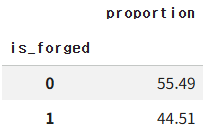

In [28]:
# code here
q1 = (df["is_forged"].value_counts(normalize=True) * 100).round(2)
q1.to_csv("forged01.csv")


**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- wavelet_skewness 값이 0보타 큰 지폐들 중, 진짜 지폐의 비율을 소수점 2자리까지 구하세요.
-  wavelet_variance 값이 상위 10%에 해당하는 지폐들 중, 위조 지폐가 차지하는 비율을 소수점 2자리까지 구하세요.

찾아낸 값들을 "ans"행에 순서대로 저장하여 제출합니다.

-HINT : 상위 x%는 Series.quantile()을 활용할 수 있습니다.

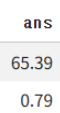

In [53]:
# code here
q2_1 = (df[df["wavelet_skewness"] > 0]["is_forged"].value_counts(normalize=True) * 100).round(2)[0]
q2_2 = (df[df["wavelet_variance"] > df["wavelet_variance"].quantile(0.9)]["is_forged"].value_counts(normalize=True) * 100).round(2)[1]

pd.DataFrame([q2_1, q2_2], columns=["ans"]).to_csv("forged02.csv", index=False)

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- is_forged들의 그룹별로 각 숫자형 컬럼의 평균을 소수점 2자리 까지 구해 주세요.
- 단, note_id는 제외합니다.

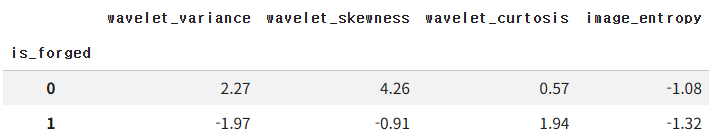

In [58]:
# code here
df_forged = df.drop("note_id", axis = 1)
df_forged
df_forged.groupby("is_forged").mean().round(2).to_csv("forged03.csv")

### **2-2. 데이터 시각화**

**Q1. is_forged 클래스별 개수를 막대그래프로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

<Axes: xlabel='is_forged', ylabel='count'>

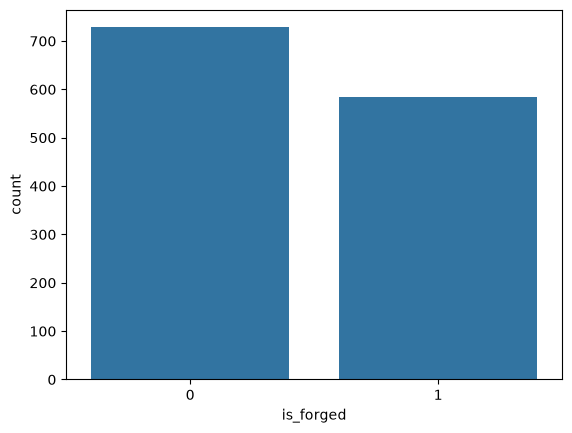

In [64]:
# code 
sns.countplot(data=df, x = "is_forged")

**Q2. wavelet_variance를 진짜, 위조 그룹별로 나누어 박스플롯으로 시각화하고 이상치를 확인하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

<Axes: xlabel='wavelet_variance'>

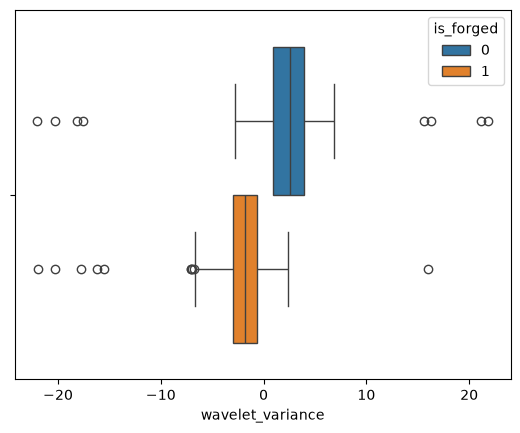

In [97]:
# code here
sns.boxplot(df, x = "wavelet_variance", hue="is_forged", orient='h')



**Q3. 4개 수치형 컬럼의 분포를 히스토그램으로 시각화하세요.**

- note_id 컬럼은 제외합니다.

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

<Axes: ylabel='Count'>

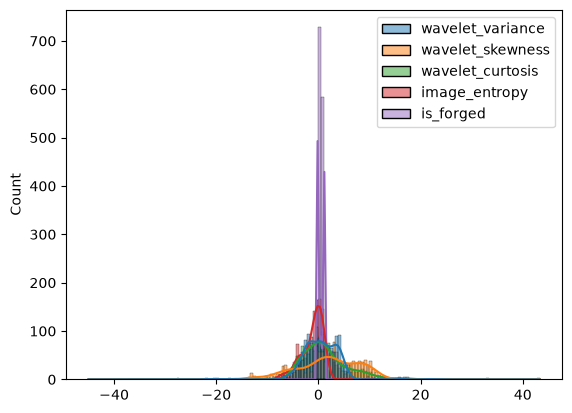

In [103]:
# code here
#numeric_cols = df.select_dtypes(include=["int64", "float64"])

df_numeric = df.drop("note_id", axis = 1)
sns.histplot(df_numeric, kde = True)

**Q4. pairplot을 그리고 각 수치형 컬럼의 관계를 확인하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

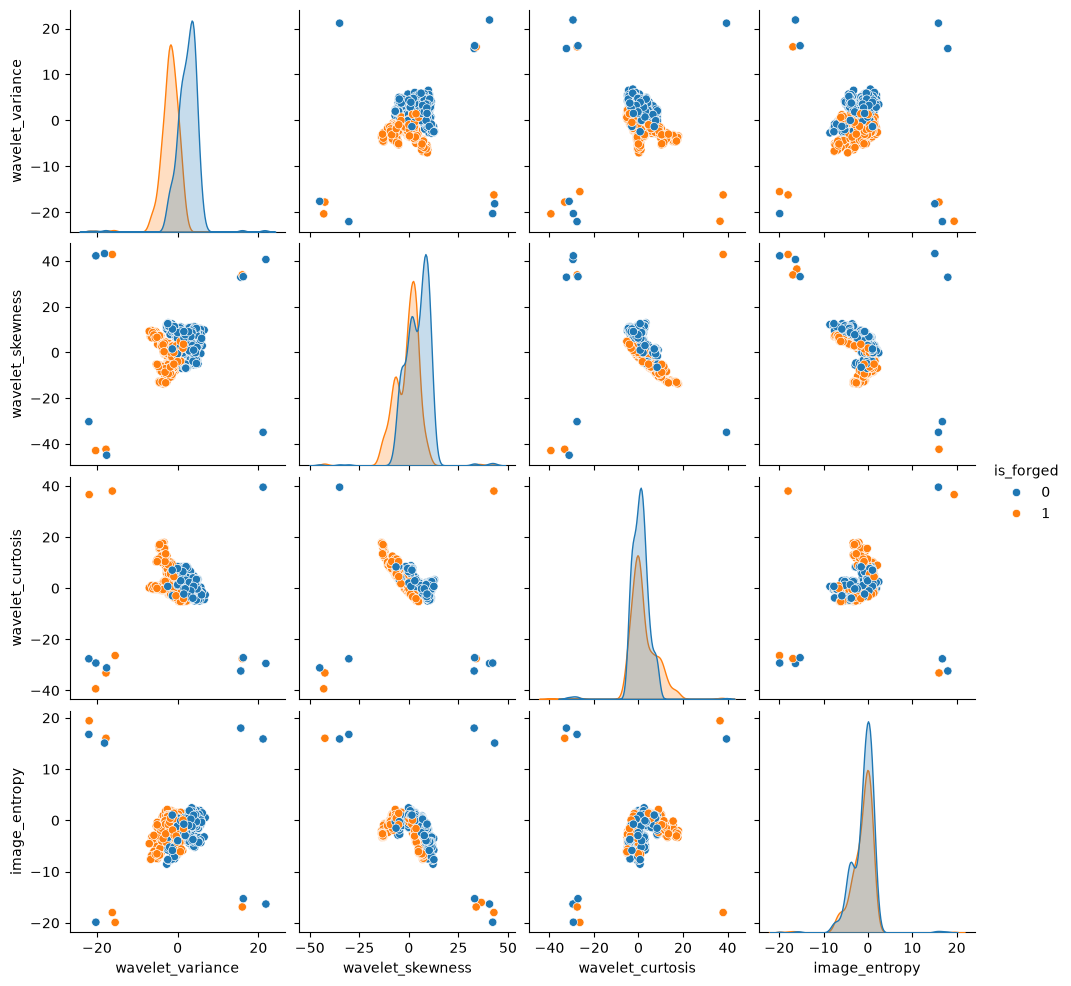

In [106]:
# code here
sns.pairplot(df_numeric, hue = "is_forged")

## **3. 데이터 전처리하기**

In [107]:
# 데이터를 전처리하다 망가트리면 여기서부터 재시작!
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery.csv")
df.head()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,1475,-0.7869,9.5663,-3.7867,-7.5034,0
1,2272,4.3239,-4.8835,3.4356,-0.5776,0
2,1867,-2.4953,11.1472,1.9353,-3.4638,0
3,1270,-1.6386,3.3584,-1.7302,NaN,1
4,2224,-2.5373,-6.9590,8.8054,1.5289,1


### **3.1 중복 행 제거하기**

**Q1. note_id를 제외한 특징들의 값이 완전히 동일한 중복 행의 개수를 찾아보세요.**

In [10]:
# code here
df_new = df.drop("note_id",axis = 1)
# print(df_new.info())
# print(df_new.value_counts())

df_new.duplicated().sum()
df_new


,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,-0.78690,9.5663,-3.7867,-7.50340,0
1,4.32390,-4.8835,3.4356,-0.57760,0
2,-2.49530,11.1472,1.9353,-3.46380,0
3,-1.63860,3.3584,-1.7302,NaN,1
4,-2.53730,-6.9590,8.8054,1.52890,1
...,...,...,...,...,...
1307,-5.06760,-5.1877,10.4266,-0.86725,1
1308,-0.93587,-5.1008,4.5367,1.38660,1
1309,-1.33890,1.5520,7.0806,1.03100,0
1310,1.53560,9.1772,-2.2718,-0.73535,0


**Q2. note_id를 제외한 특징들의 값이 완전히 동일한 중복 행들을 삭제해 주세요.**

In [12]:
# code here
df_new.drop_duplicates()

,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,-0.78690,9.5663,-3.7867,-7.50340,0
1,4.32390,-4.8835,3.4356,-0.57760,0
2,-2.49530,11.1472,1.9353,-3.46380,0
3,-1.63860,3.3584,-1.7302,NaN,1
4,-2.53730,-6.9590,8.8054,1.52890,1
...,...,...,...,...,...
1307,-5.06760,-5.1877,10.4266,-0.86725,1
1308,-0.93587,-5.1008,4.5367,1.38660,1
1309,-1.33890,1.5520,7.0806,1.03100,0
1310,1.53560,9.1772,-2.2718,-0.73535,0


### **3.2 데이터 분리하기**

**Q1. 학습 데이터와 테스트 데이터를 분리한다.**

- note_id를 제외한 수치형 컬럼을 X, is_forged 컬럼을 y로 지정한다.
- test 데이터의 비율은 30%로 한다.
- 재현성을 위해 random_state=42로 설정한다.

In [15]:
# code here
X = df_new.drop("is_forged", axis = 1)
y = df_new["is_forged"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,  y, test_size=0.3, random_state=42)

### **3.2 결측치 처리**

**Q1. 각 컬럼별 결측치의 개수를 확인해봅시다.**

In [18]:
# code here
X_train.isnull().sum()
X_test.isnull().sum()

wavelet_variance    22
wavelet_skewness    19
wavelet_curtosis    11
image_entropy       35
dtype: int64

**Q2. 각 컬렄들의 결측치를 중앙값(median)으로 채우세요.**

- 테스트 데이터의 결측치도 학습 데이터의 median으로 채워줘야 data leakage를 방지할 수 있습니다.

In [20]:
# code here
numeric_cols = X_train.select_dtypes(include="number").columns
fill_values = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(fill_values)

X_train.isnull().sum()

wavelet_variance    0
wavelet_skewness    0
wavelet_curtosis    0
image_entropy       0
dtype: int64

In [21]:
X_test[numeric_cols] = X_test[numeric_cols].fillna(fill_values)
X_test.isnull().sum()

wavelet_variance    0
wavelet_skewness    0
wavelet_curtosis    0
image_entropy       0
dtype: int64

### **3.3 이상치 처리**

**Q1. IQR을 활용해서 각 컬럼에 총 몇개의 이상치가 있는지를 확인해보자.**

In [22]:
# outlier = 이상치
# 몇개가 있느냐? 좌측 whisker, 우측 whisker를 벗어나는 데이터의 개수
# 좌측 whisker : 25% * 1.5배까지 유예
# 우측 whisker : 75% * 1.5배까지 유예


# data: dataframe
# column: 이 dataframe의 어떤 열에 대해서 whisker를 찾으려고 하는지
def find_whiskers(data, column):
    #1. 25%, 75% quantile 찾기
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    #2. Inter Quntail Range구하기
    iqr = Q3 - Q1
    #3. 좌측 whisker와 우측 whisker를 구하기
    lower = Q1 - (1.5 * iqr)
    upper = Q3 + (1.5 * iqr)

    return (lower,upper)

In [23]:
# code here
# lower와 upper whisker를 dataframe 각각의 column마다 찾아낼 수 있음
# column에서 이 lower보다 작거나, upper보다 큰 값 -> 이상치

numeric_cols = X_train.select_dtypes(include = "number").columns

d = {} #key: 컬럼명, value : 튜플로 (lower, upper) <-한계치 이거보다 높거나 작은거는 채움

for c in numeric_cols:               #하나씩 열에 접근
    # lower, upper whisker를 만들어준 함수로 찾아옴
    lower, upper = find_whiskers(X_train, c)
    d[c] = (lower, upper)
    count = ((X_train[c] < lower) | (X_train[c] > upper)).sum() #lower보다 작거나 upper보다 큰 값 개수 세기
    print(f"{c} {count}개")
    # print(f"{c} : {lower}, {upper}")


wavelet_variance 10개
wavelet_skewness 24개
wavelet_curtosis 44개
image_entropy 45개


**Q2. 이상치를 처리합니다.**

- 각 특징 컬럼의 값을 [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR] 범위로 clipping(capping)하세요.

In [24]:
# code here
# clip()
for c in numeric_cols:
    # 1. 우리가 찾아둔 lower, upper whisker를 가져옴
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower,upper) # lower 보다 작은거는 lower, upper보다 작은 거는 upper
    # test_data에도 이상치가 있음. -> train 데이터의 lower와 upper whisker로 clipping
    X_test[c] = X_test[c].clip(lower, upper)

In [25]:
for c in numeric_cols:
    # 다시 find_whisker를 하면 또 이상치가 생길 수 있으므로.
    count = ((X_train[c] < d[c][0]) | (X_train[c] > d[c][1])).sum()
    print(f"{c} : {count}개")

wavelet_variance : 0개
wavelet_skewness : 0개
wavelet_curtosis : 0개
image_entropy : 0개


## **4. 모델 학습 및 평가**

### **4.1 모델 학습**

**Q1. LogisticRegression 모델을 생성하고 학습시킵니다.**

In [26]:
# code here
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### **4.2 예측하기**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

예측값은 y_pred 에 저장합니다.

In [27]:
# code here
y_pred = model.predict(X_test)

### **4.3 모델 평가**

**Q1. 정확도를 활용해 모델 성능을 평가하세요.**

In [28]:
# code here
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.949238578680203

**Q2. 혼돈행렬을 그려 모델 성능을 평가하세요.**

In [31]:
# code here
from sklearn.metrics import confusion_matrix
import seaborn as sns

confusion_matrix(y_test, y_pred)
# sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot = True)

array([[209,   9],
       [ 11, 165]])

## **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "is_forged" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery_submission.csv

In [32]:
sub = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery_submission.csv")
sub.head()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy
0,5001,-4.8426,-4.99320,10.40520,-0.53104
1,5002,2.9742,8.96000,-2.90240,-1.03790
2,5003,-5.4414,7.23630,0.10938,-7.56420
3,5004,1.9410,0.46351,4.64720,1.08790
4,5005,1.9476,-4.77380,8.52700,-1.86680


In [ ]:
# code here
X_new_test = sub.drop("note_id", axis = 1)
X_new_test

wavelet_variance    0
wavelet_skewness    0
wavelet_curtosis    0
image_entropy       0
dtype: int64

In [ ]:
numeric_cols = X_new_test.select_dtypes(include = "number").columns

d = {} #key: 컬럼명, value : 튜플로 (lower, upper) <-한계치 이거보다 높거나 작은거는 채움

for c in numeric_cols:               #하나씩 열에 접근
    # lower, upper whisker를 만들어준 함수로 찾아옴
    lower, upper = find_whiskers(X_new_test, c)
    d[c] = (lower, upper)
    count = ((X_new_test[c] < lower) | (X_new_test[c] > upper)).sum() #lower보다 작거나 upper보다 큰 값 개수 세기
    print(f"{c} {count}개")
    # print(f"{c} : {lower}, {upper}")



wavelet_variance 0개
wavelet_skewness 0개
wavelet_curtosis 7개
image_entropy 6개


In [42]:
# clip()
for c in numeric_cols:
    # 1. 우리가 찾아둔 lower, upper whisker를 가져옴
    lower, upper = d[c]
    X_new_test[c] = X_new_test[c].clip(lower,upper) # lower 보다 작은거는 lower, upper보다 작은 거는 upper
    # test_data에도 이상치가 있음. -> train 데이터의 lower와 upper whisker로 clipping
    X_new_test[c] = X_new_test[c].clip(lower, upper)

In [43]:
for c in numeric_cols:
    # 다시 find_whisker를 하면 또 이상치가 생길 수 있으므로.
    count = ((X_new_test[c] < d[c][0]) | (X_new_test[c] > d[c][1])).sum()
    print(f"{c} : {count}개")

wavelet_variance : 0개
wavelet_skewness : 0개
wavelet_curtosis : 0개
image_entropy : 0개


In [44]:
y_pred = model.predict(X_new_test)

In [47]:
pd.DataFrame(y_pred, columns=["is_forged"]).to_csv("forged04.csv", index=False)